# BÀI TẬP LỚN HỌC PHẦN NHẬP MÔN HỌC MÁY (FIT4013)
## ĐỀ TÀI 13: DỰ ĐOÁN NHÂN VIÊN CÓ KHẢ NĂNG NGHỈ VIỆC (HR EMPLOYEE ATTRITION)

---
### Mục tiêu & Quy trình thực hiện
Notebook này trình bày toàn bộ quy trình học máy (Machine Learning Pipeline) từ dữ liệu thô đến đánh giá và phân tích lỗi theo đúng yêu cầu của học phần **FIT4013**:
1. **Khám phá và phân tích dữ liệu (EDA)**: Kiểm tra cấu trúc, phân phối nhãn mất cân bằng (`Attrition`), phân tích đặc trưng số, đặc trưng phân loại, ngoại lệ (outliers), đa cộng tuyến và các cột không mang thông tin (`EmployeeCount`, `Over18`, `StandardHours`, `EmployeeNumber`).
2. **Thiết kế 2 luồng tiền xử lý & Kỹ thuật đặc trưng (Data Preprocessing & Feature Engineering)**:
   - **Luồng A (Pipeline cơ bản)**: Loại bỏ cột hằng số/định danh, mã hóa `OneHotEncoder(drop='first')` cho biến phân loại, chuẩn hóa `StandardScaler` cho biến số.
   - **Luồng B (Pipeline cải tiến)**: Tạo 8 đặc trưng nghiệp vụ nhân sự mới (`TotalSatisfaction`, `IncomePerWorkingYear`, `StagnationRatio`, `JobHoppingRate`, `NewHireRisk`, `OverTime_Single_Risk`, `OverTime_LowSat_Risk`, `CommuteBurden`), loại bỏ các biến nhiễu phân phối đều (`DailyRate`, `HourlyRate`, `MonthlyRate`) và biến đa cộng tuyến mạnh (`JobLevel`, `PercentSalaryHike`), sử dụng `RobustScaler` chống ngoại lệ và chọn lọc đặc trưng `SelectKBest(f_classif)`.
3. **Huấn luyện & Tinh chỉnh siêu tham số (Model Training & Hyperparameter Tuning)**:
   - So sánh 3 thuật toán cốt lõi của học phần: **K-Nearest Neighbors (K-NN)**, **Gaussian Naive Bayes**, **Decision Tree (Cây quyết định)**.
   - Mở rộng (Bonus): **Random Forest Classifier** (Ensemble Learning).
4. **Đánh giá toàn diện & Phân tích lỗi (Evaluation & Error Analysis)**:
   - Đánh giá qua `Accuracy`, `Precision`, `Recall`, `F1-score`, `ROC-AUC` và `Confusion Matrix` (ưu tiên `F1-score` và `Recall` do dữ liệu mất cân bằng 83.9% : 16.1%).
   - Phân tích sâu các trường hợp dự đoán sai **False Negative (FN)** và **False Positive (FP)** gắn với bối cảnh quản trị nhân sự.


In [1]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')

# Thêm thư mục gốc vào sys.path để import module src
sys.path.append(os.path.abspath('..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

from src.pipeline import (
    HRFeatureEngineer,
    load_and_split_data,
    build_preprocessor_stream_a,
    build_preprocessor_stream_b,
    RANDOM_STATE,
    DROP_COLS_BASIC,
    CAT_COLS
)

sns.set_theme(style="whitegrid", palette="muted")
print("Khởi tạo môi trường thành công! Random State =", RANDOM_STATE)


Khởi tạo môi trường thành công! Random State = 42


---
## 1. Khám phá và Phân tích Dữ liệu (Exploratory Data Analysis - EDA)
### 1.1. Tải dữ liệu, kiểm tra kích thước, dữ liệu thiếu và trùng lặp

In [2]:
CSV_PATH = os.path.abspath('../WA_Fn-UseC_-HR-Employee-Attrition.csv')
df, X_train, X_test, y_train, y_test = load_and_split_data(CSV_PATH, test_size=0.2, random_state=RANDOM_STATE)

print(f"Kích thước toàn bộ tập dữ liệu: {df.shape[0]} dòng x {df.shape[1]} cột")
print(f"Kích thước tập Huấn luyện (Train): {X_train.shape[0]} mẫu (80%)")
print(f"Kích thước tập Kiểm thử (Test):    {X_test.shape[0]} mẫu (20%)")
print(f"Số giá trị bị thiếu (Missing values): {df.isnull().sum().sum()}")
print(f"Số dòng trùng lặp hoàn toàn (Duplicates): {df.duplicated().sum()}")

# Kiểm tra các cột chỉ có 1 giá trị duy nhất (hằng số) hoặc cột định danh
constant_or_id = [col for col in df.columns if df[col].nunique() == 1 or df[col].nunique() == len(df)]
print("Các cột hằng số hoặc định danh duy nhất:", constant_or_id)
df.head(5)


Kích thước toàn bộ tập dữ liệu: 1470 dòng x 35 cột
Kích thước tập Huấn luyện (Train): 1176 mẫu (80%)
Kích thước tập Kiểm thử (Test):    294 mẫu (20%)
Số giá trị bị thiếu (Missing values): 0
Số dòng trùng lặp hoàn toàn (Duplicates): 0
Các cột hằng số hoặc định danh duy nhất: ['EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours']


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


### 1.2. Phân tích biến mục tiêu (`Attrition`)
Biến mục tiêu `Attrition` gồm 2 nhãn: `No` (Nhân viên ở lại) và `Yes` (Nhân viên nghỉ việc).

In [3]:
target_counts = df['Attrition'].value_counts()
target_pct = df['Attrition'].value_counts(normalize=True) * 100
summary_target = pd.DataFrame({'Số lượng': target_counts, 'Tỷ lệ (%)': target_pct.round(2)})
display(summary_target)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['No (Ở lại)', 'Yes (Nghỉ việc)'], [target_counts['No'], target_counts['Yes']],
              color=['#2b5c8f', '#d95f02'], width=0.5, edgecolor='black')
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 20, f"{h} ({h/len(df)*100:.1f}%)", ha='center', fontweight='bold')
ax.set_ylim(0, 1400)
ax.set_title("Phân phối biến mục tiêu Attrition (N = 1,470)", fontweight='bold')
ax.set_ylabel("Số lượng nhân viên")
plt.show()


,Số lượng,Tỷ lệ (%)
Attrition,,
No,1233,83.88
Yes,237,16.12


**Nhận xét quan trọng từ phân phối nhãn**:
- Tập dữ liệu bị **mất cân bằng lớp (class imbalance)** rõ rệt: lớp `No` chiếm **83.88%** (1,233 mẫu) trong khi lớp `Yes` chỉ chiếm **16.12%** (237 mẫu), tỷ lệ xấp xỉ **5.2 : 1**.
- Nếu một mô hình ngây thơ dự đoán tất cả nhân viên đều "Ở lại (`No`)", nó vẫn đạt `Accuracy = 83.88%` nhưng `Recall = 0%` và `F1-score = 0%` trên lớp nghỉ việc. Do đó, chúng ta **bắt buộc phải sử dụng `F1-score`, `Recall`, `Precision` và `ROC-AUC`** làm tiêu chí đánh giá chính thay vì chỉ nhìn vào `Accuracy`.

### 1.3. Phân tích đặc trưng số, ngoại lệ (Outliers) và đặc trưng phân loại

In [4]:
df_eda = df.copy()
df_eda['Attrition_num'] = (df_eda['Attrition'] == 'Yes').astype(int)

# Thống kê mô tả các đặc trưng số quan trọng
key_num_cols = ['Age', 'MonthlyIncome', 'TotalWorkingYears', 'YearsAtCompany',
                'YearsSinceLastPromotion', 'DistanceFromHome', 'NumCompaniesWorked', 'DailyRate']
display(df[key_num_cols].describe().T[['mean', 'std', 'min', '50%', 'max']])

# Boxplot kiểm tra phân phối và ngoại lệ theo Attrition
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for idx, col in enumerate(['MonthlyIncome', 'TotalWorkingYears', 'Age']):
    sns.boxplot(data=df_eda, x='Attrition', y=col, hue='Attrition', legend=False,
                palette={'No': '#4c72b0', 'Yes': '#dd8452'}, width=0.45, ax=axes[idx])
    axes[idx].set_title(f"Phân phối {col} theo Attrition", fontweight='bold')
plt.tight_layout()
plt.show()


,mean,std,min,50%,max
Age,36.923810,9.135373,18.0,36.0,60.0
MonthlyIncome,6502.931293,4707.956783,1009.0,4919.0,19999.0
TotalWorkingYears,11.279592,7.780782,0.0,10.0,40.0
YearsAtCompany,7.008163,6.126525,0.0,5.0,40.0
YearsSinceLastPromotion,2.187755,3.222430,0.0,1.0,15.0
DistanceFromHome,9.192517,8.106864,1.0,7.0,29.0
NumCompaniesWorked,2.693197,2.498009,0.0,2.0,9.0
DailyRate,802.485714,403.509100,102.0,802.0,1499.0


In [5]:
# Tỷ lệ nghỉ việc theo các biến phân loại quan trọng
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for idx, col in enumerate(['OverTime', 'MaritalStatus', 'BusinessTravel']):
    rate_df = df_eda.groupby(col)['Attrition_num'].agg(['count', 'mean']).reset_index()
    rate_df['pct'] = rate_df['mean'] * 100
    axes[idx].bar(rate_df[col], rate_df['pct'], color='#3b75af', edgecolor='black', width=0.5)
    for i, (v, cnt) in enumerate(zip(rate_df['pct'], rate_df['count'])):
        axes[idx].text(i, v + 0.8, f"{v:.1f}%\n(n={cnt})", ha='center', fontsize=9)
    axes[idx].set_ylim(0, 38)
    axes[idx].set_title(f"Tỷ lệ nghỉ việc theo {col}", fontweight='bold')
    axes[idx].set_ylabel("Tỷ lệ nghỉ việc (%)")
plt.tight_layout()
plt.show()

# Kiểm tra tương quan với Attrition_num
num_only = [c for c in df_eda.select_dtypes(include=[np.number]).columns if c not in DROP_COLS_BASIC + ['Attrition_num']]
corrs = df_eda[num_only + ['Attrition_num']].corr()['Attrition_num'].drop('Attrition_num').sort_values()
print("Top 5 biến tương quan âm mạnh nhất với nghỉ việc:")
print(corrs.head(5))
print("\nCác biến có tương quan gần bằng 0 (nhiễu tiềm năng):")
print(corrs[corrs.abs() < 0.02])


Top 5 biến tương quan âm mạnh nhất với nghỉ việc:
TotalWorkingYears    -0.171063
JobLevel             -0.169105
YearsInCurrentRole   -0.160545
MonthlyIncome        -0.159840
Age                  -0.159205
Name: Attrition_num, dtype: float64

Các biến có tương quan gần bằng 0 (nhiễu tiềm năng):
PercentSalaryHike   -0.013478
HourlyRate          -0.006846
PerformanceRating    0.002889
MonthlyRate          0.015170
Name: Attrition_num, dtype: float64


---
## 2. Tiền xử lý và Kỹ thuật Đặc trưng: So sánh Luồng A và Luồng B

Theo hướng dẫn thực hiện đối với dữ liệu dạng bảng (Phần 5.1), chúng ta thiết kế và đối chiếu hai cấu hình xử lý dữ liệu độc lập trên cùng tập `X_train` / `X_test`:

| Tiêu chí | **Luồng A: Pipeline cơ bản (Baseline Prep)** | **Luồng B: Pipeline cải tiến (Improved Prep)** |
| :--- | :--- | :--- |
| **Xử lý cột thừa/nhiễu** | Chỉ bỏ 3 cột hằng số (`EmployeeCount`, `Over18`, `StandardHours`) và 1 cột ID (`EmployeeNumber`). | Bỏ thêm 3 cột lương/tỷ lệ ngẫu nhiên không có tương quan (`DailyRate`, `HourlyRate`, `MonthlyRate`) và 2 cột đa cộng tuyến cao (`JobLevel` có $r=0.95$ với `MonthlyIncome`, `PercentSalaryHike` có $r=0.77$ với `PerformanceRating`). |
| **Tạo đặc trưng mới (Feature Engineering)** | Không tạo đặc trưng mới. | Xây dựng `HRFeatureEngineer` tạo **8 đặc trưng nghiệp vụ HR**: `TotalSatisfaction`, `IncomePerWorkingYear`, `StagnationRatio`, `JobHoppingRate`, `NewHireRisk`, `OverTime_Single_Risk`, `OverTime_LowSat_Risk`, `CommuteBurden`. |
| **Chuẩn hóa biến số** | `StandardScaler` (nhạy cảm với ngoại lệ lệch phải của `MonthlyIncome`, `YearsAtCompany`). | `RobustScaler` (chuẩn hóa theo trung vị và IQR, kháng ngoại lệ tốt hơn). |
| **Chọn lọc đặc trưng** | Giữ toàn bộ đặc trưng sau mã hóa (44 chiều). | Kết hợp `SelectKBest(f_classif)` cho các mô hình nhạy cảm với số chiều như K-NN. |


In [6]:
prep_A = build_preprocessor_stream_a(X_train)
prep_B_all = build_preprocessor_stream_b(X_train, k_best=None)
prep_B_k15 = build_preprocessor_stream_b(X_train, k_best=15)

X_tr_A = prep_A.fit_transform(X_train, y_train)
X_tr_B_all = prep_B_all.fit_transform(X_train, y_train)
X_tr_B_k15 = prep_B_k15.fit_transform(X_train, y_train)

print(f"Số chiều đặc trưng sau Luồng A (Cơ bản):              {X_tr_A.shape[1]} đặc trưng")
print(f"Số chiều đặc trưng sau Luồng B (Cải tiến - đầy đủ):   {X_tr_B_all.shape[1]} đặc trưng")
print(f"Số chiều đặc trưng sau Luồng B (Cải tiến - Top 15):   {X_tr_B_k15.shape[1]} đặc trưng")

# Kiểm chứng tương quan của các đặc trưng mới tạo với biến mục tiêu trên tập Train
fe_train = HRFeatureEngineer(drop_noisy=True).fit_transform(X_train)
fe_train['Attrition_num'] = y_train.values
new_cols = ['TotalSatisfaction', 'IncomePerWorkingYear', 'StagnationRatio', 'JobHoppingRate',
            'NewHireRisk', 'OverTime_Single_Risk', 'OverTime_LowSat_Risk', 'CommuteBurden']
print("\nHệ số tương quan Pearson của 8 đặc trưng mới với Attrition trên tập Train:")
print(fe_train[new_cols + ['Attrition_num']].corr()['Attrition_num'].drop('Attrition_num').sort_values(ascending=False).round(4))


Số chiều đặc trưng sau Luồng A (Cơ bản):              44 đặc trưng
Số chiều đặc trưng sau Luồng B (Cải tiến - đầy đủ):   47 đặc trưng
Số chiều đặc trưng sau Luồng B (Cải tiến - Top 15):   15 đặc trưng

Hệ số tương quan Pearson của 8 đặc trưng mới với Attrition trên tập Train:
OverTime_Single_Risk    0.2670
OverTime_LowSat_Risk    0.2577
JobHoppingRate          0.2133
NewHireRisk             0.1978
CommuteBurden           0.1675
IncomePerWorkingYear    0.1294
StagnationRatio         0.0015
TotalSatisfaction      -0.1679
Name: Attrition_num, dtype: float64


---
## 3. Huấn luyện Mô hình, Tinh chỉnh Siêu tham số và So sánh Kết quả

Chúng ta thực hiện huấn luyện và đánh giá bằng **5-Fold Stratified Cross-Validation** trên tập Train (1,176 mẫu) và kiểm tra độc lập trên tập Test (294 mẫu) đối với 3 thuật toán đã học:
1. **K-Nearest Neighbors (K-NN)**: So sánh cấu hình mặc định (`k=5, Euclidean, uniform`) và cấu hình tinh chỉnh (`k=7/11, Manhattan, distance`).
2. **Gaussian Naive Bayes (GNB)**: So sánh cấu hình mặc định (`var_smoothing=1e-9`) và cấu hình làm trơn phương sai (`var_smoothing=0.1`) để hạn chế quá khớp vào các biến nhị phân sau One-Hot Encoding.
3. **Cây quyết định (Decision Tree)**: So sánh cây mặc định (`max_depth=None` - dễ bị overfitting vào lớp đa số) và cây cắt tỉa có trọng số lớp cân bằng (`max_depth=4, min_samples_leaf=15, class_weight='balanced'`).
4. **Mở rộng (Random Forest Ensemble)**: Kết hợp 200 cây quyết định (`max_depth=7, class_weight='balanced'`).

In [7]:
summary_df = pd.read_csv('../outputs/results/experiment_summary.csv')
display(summary_df[['Stream', 'Model', 'CV_F1_mean', 'Test_Accuracy', 'Test_Precision', 'Test_Recall', 'Test_F1', 'Test_ROC_AUC', 'TP', 'FP', 'FN', 'TN']])


,Stream,Model,CV_F1_mean,Test_Accuracy,Test_Precision,Test_Recall,Test_F1,Test_ROC_AUC,TP,FP,FN,TN
0,Luồng A (Cơ bản),"K-NN (Baseline, k=5, Euclidean)",0.2264,0.8367,0.4545,0.1064,0.1724,0.6181,5,6,42,241
1,Luồng A (Cơ bản),"K-NN (Tuned, k=11, Manhattan, dist)",0.1929,0.8401,0.5000,0.0638,0.1132,0.6921,3,3,44,244
2,Luồng A (Cơ bản),"Gaussian NB (Baseline, smooth=1e-9)",0.3902,0.6156,0.2500,0.7021,0.3687,0.6956,33,99,14,148
3,Luồng A (Cơ bản),"Gaussian NB (Tuned, smooth=0.1)",0.4745,0.7449,0.3293,0.5745,0.4186,0.7324,27,55,20,192
4,Luồng A (Cơ bản),"Decision Tree (Baseline, mặc định)",0.3714,0.7585,0.2931,0.3617,0.3238,0.5979,17,41,30,206
5,Luồng A (Cơ bản),"Decision Tree (Tuned, depth=4, balanced)",0.4217,0.7007,0.2697,0.5106,0.3529,0.6960,24,65,23,182
6,Luồng B (Cải tiến),"K-NN (Baseline, k=5, Euclidean)",0.3647,0.8333,0.4375,0.1489,0.2222,0.6596,7,9,40,238
7,Luồng B (Cải tiến),"K-NN (Tuned, k=7, Manhattan, dist)",0.3181,0.8503,0.6000,0.1915,0.2903,0.6977,9,6,38,241
8,Luồng B (Cải tiến),"Gaussian NB (Baseline, smooth=1e-9)",0.4874,0.8027,0.4247,0.6596,0.5167,0.7701,31,42,16,205
9,Luồng B (Cải tiến),"Gaussian NB (Tuned, smooth=0.1)",0.5411,0.8571,0.5490,0.5957,0.5714,0.7686,28,23,19,224


=== BIỂU ĐỒ SO SÁNH LUỒNG A VÀ LUỒNG B ===


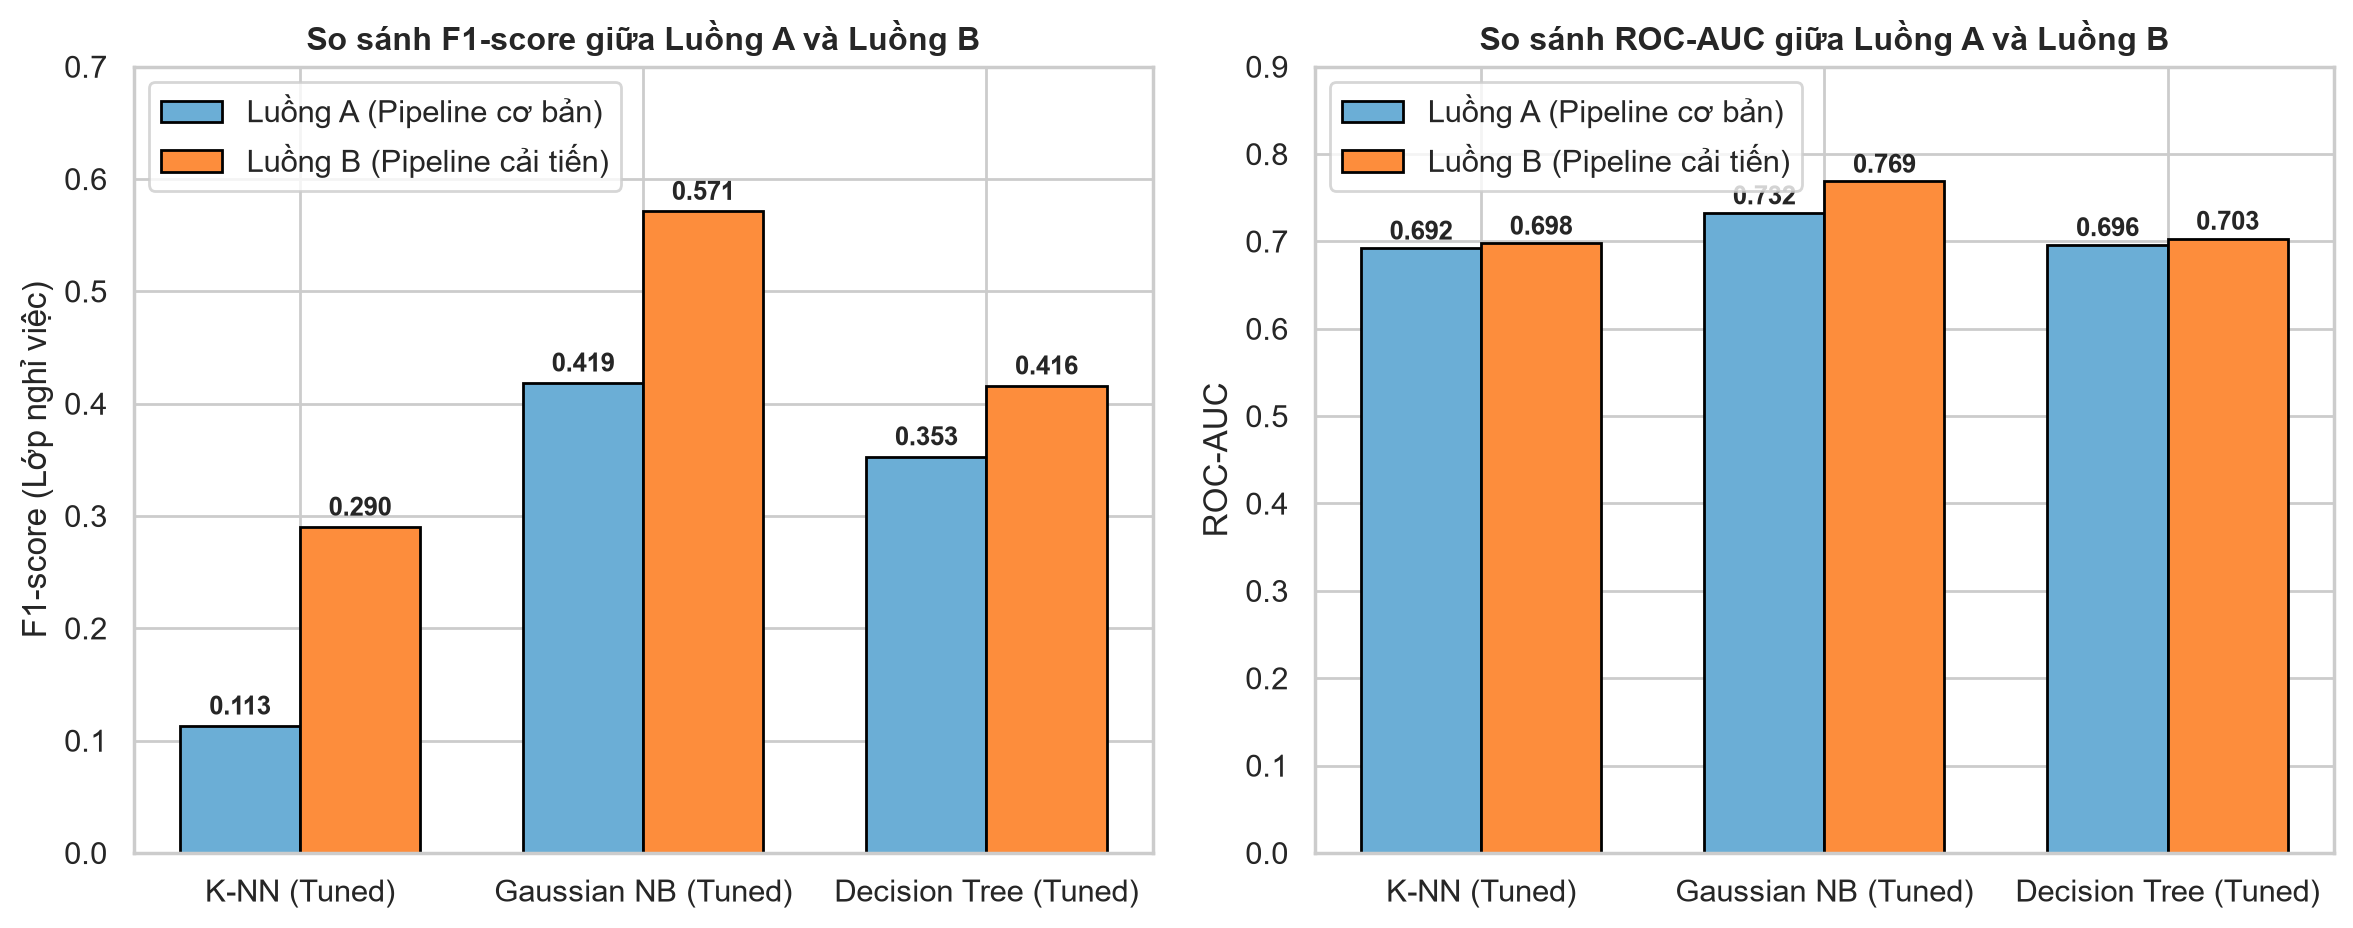


=== ẢNH HƯỞNG CỦA SIÊU THAM SỐ (HYPERPARAMETER SENSITIVITY) ===


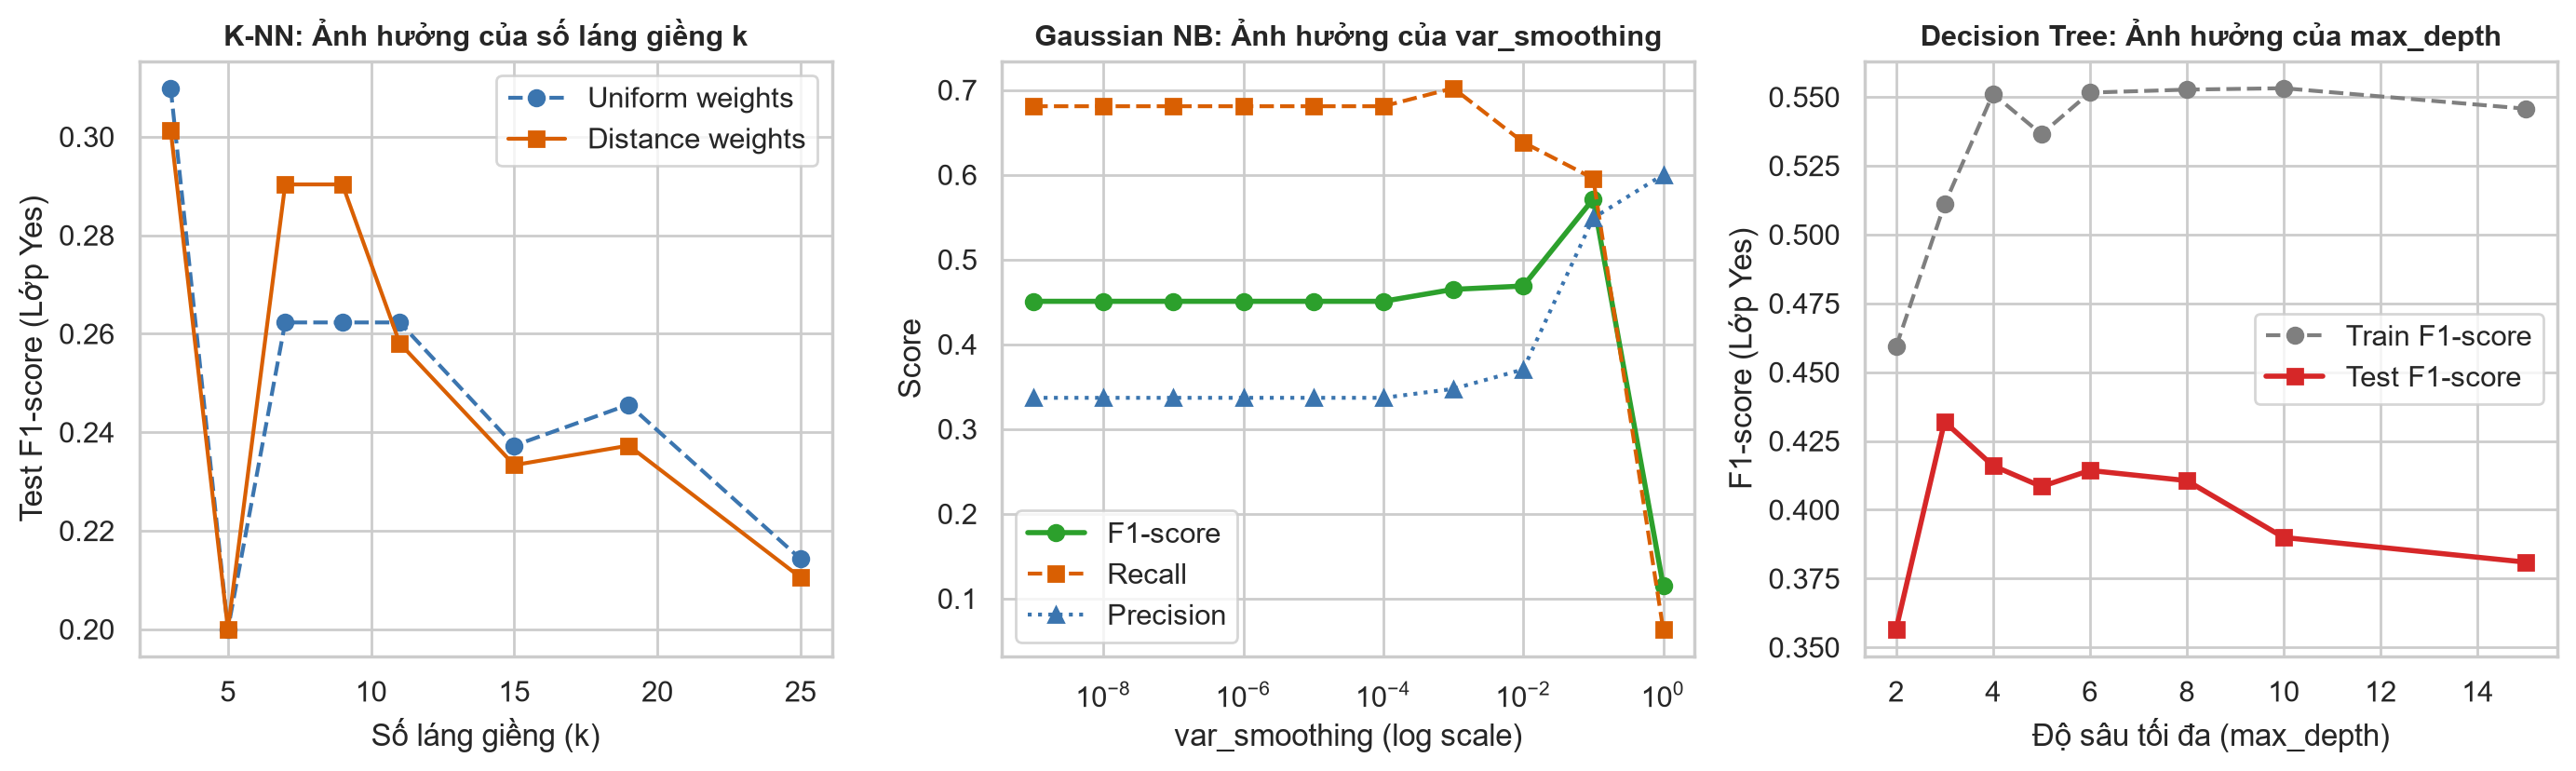


=== MA TRẬN NHẦM LẪN (CONFUSION MATRICES) & ĐƯỜNG CONG ROC ===


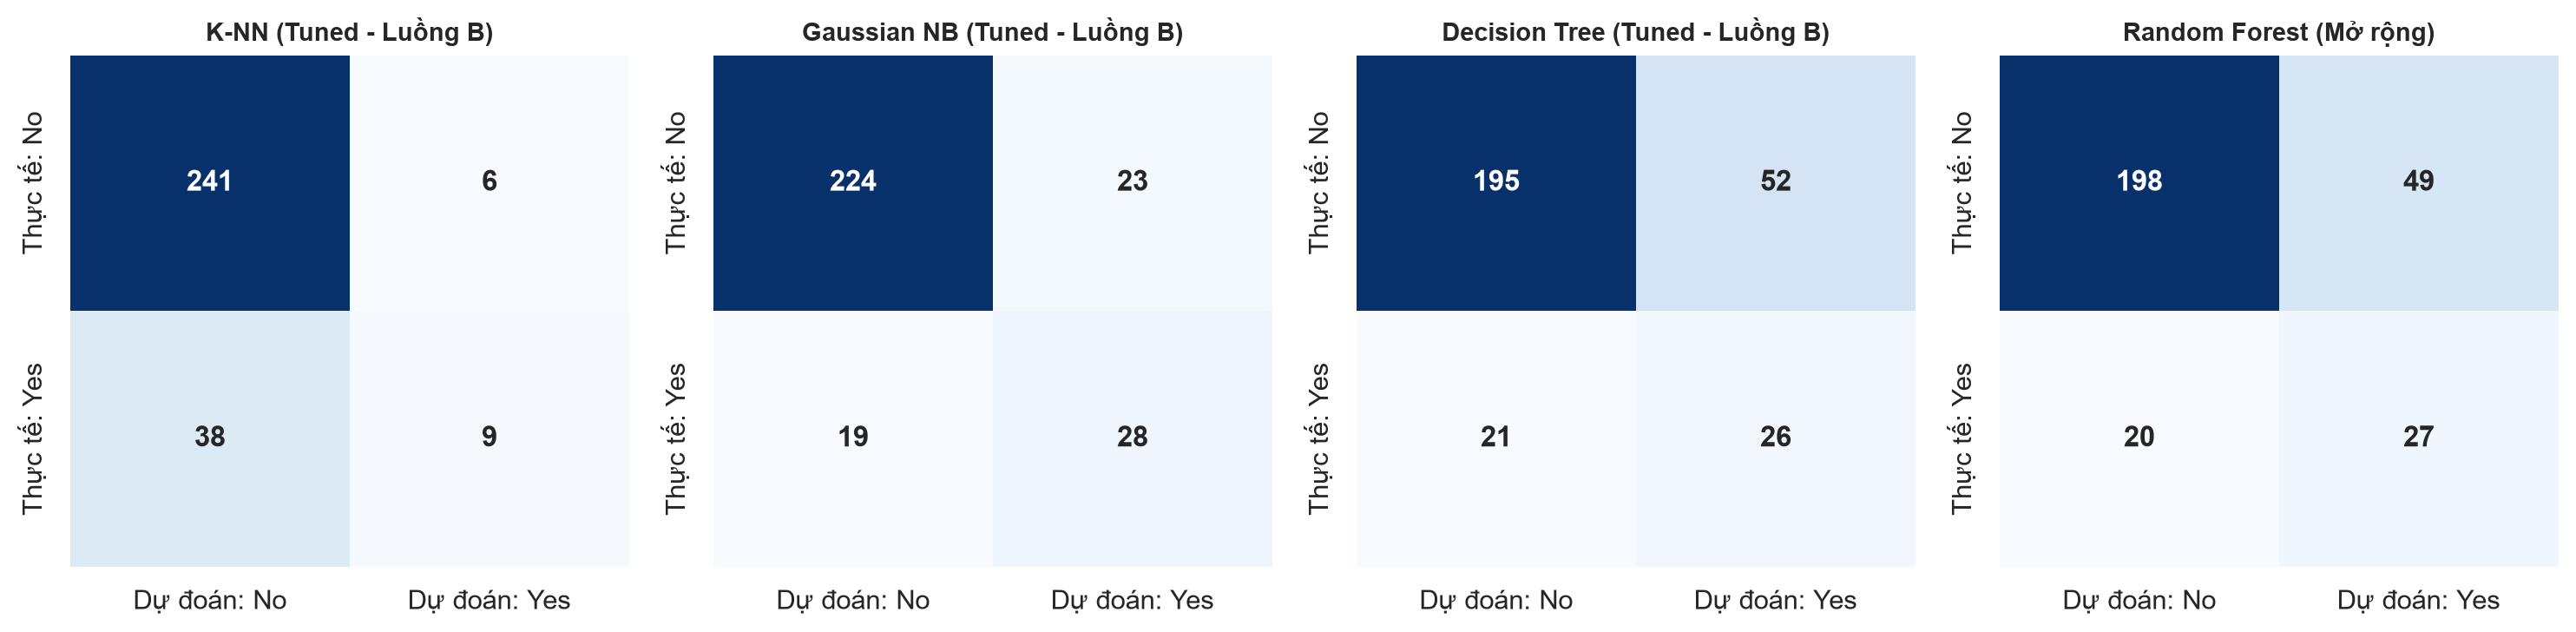

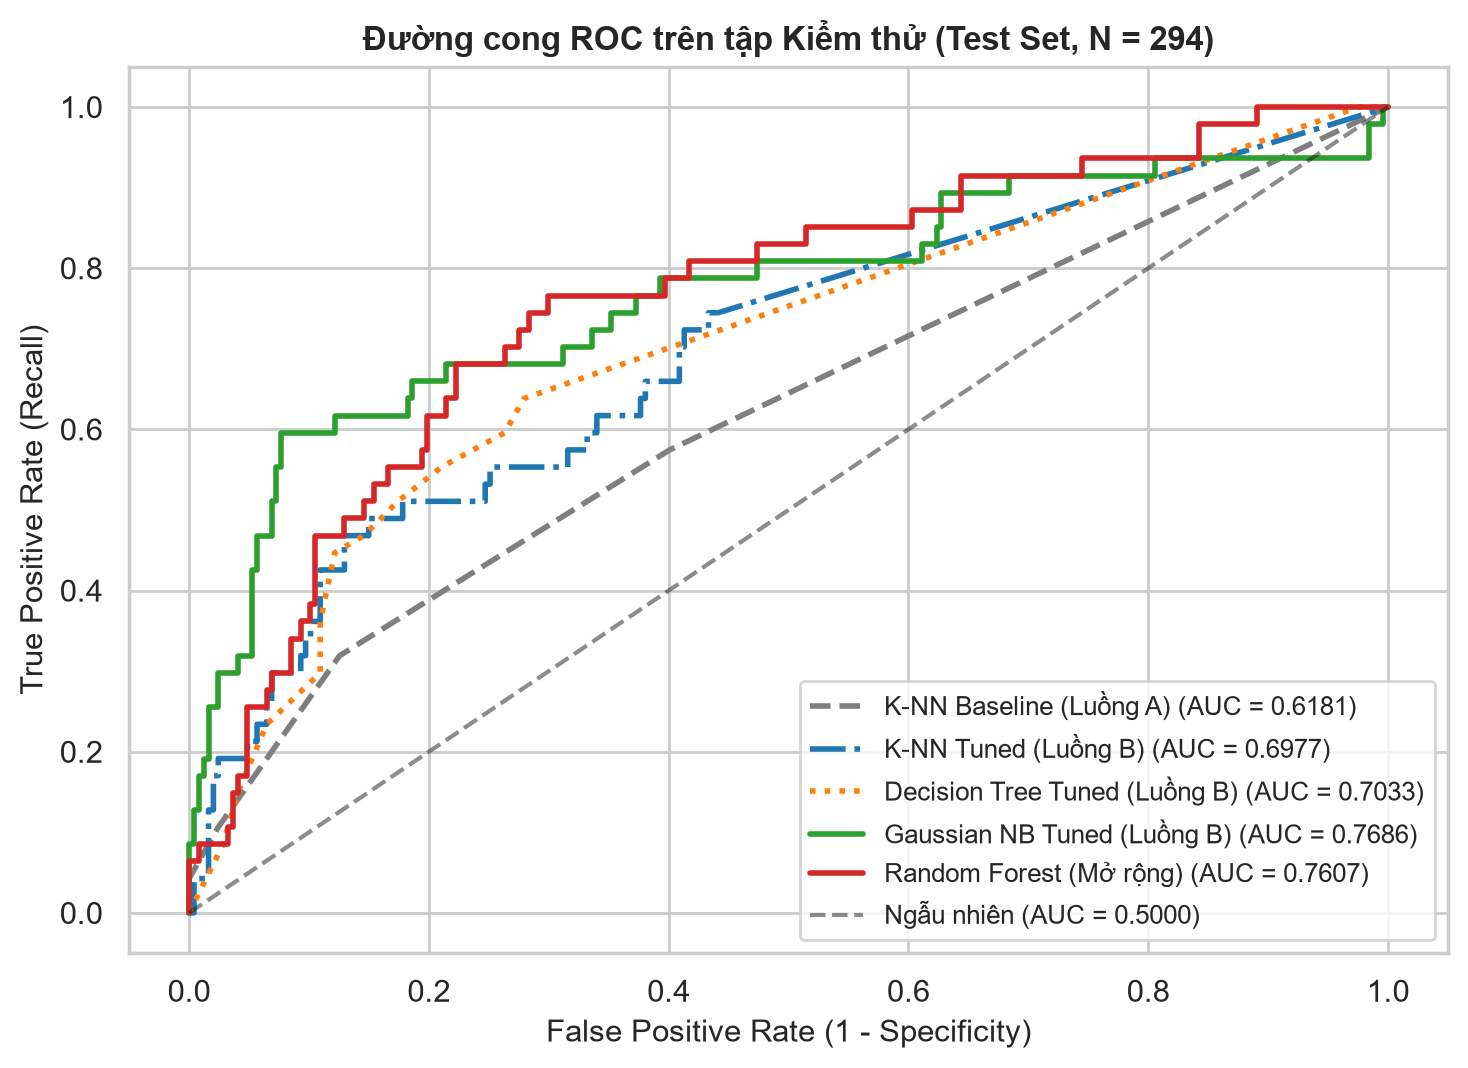

In [8]:
from IPython.display import Image, display

print("=== BIỂU ĐỒ SO SÁNH LUỒNG A VÀ LUỒNG B ===")
display(Image(filename='../outputs/figures/fig6_stream_comparison.png', width=850))

print("\n=== ẢNH HƯỞNG CỦA SIÊU THAM SỐ (HYPERPARAMETER SENSITIVITY) ===")
display(Image(filename='../outputs/figures/fig5_hyperparameter_tuning.png', width=900))

print("\n=== MA TRẬN NHẦM LẪN (CONFUSION MATRICES) & ĐƯỜNG CONG ROC ===")
display(Image(filename='../outputs/figures/fig7_confusion_matrices.png', width=950))
display(Image(filename='../outputs/figures/fig8_roc_curves.png', width=650))


---
## 4. Phân tích Lỗi (Error Analysis) và Giải thích Mô hình

Trong bài toán dự đoán nghỉ việc, hai loại lỗi mang ý nghĩa quản trị rất khác nhau:
- **False Negative (FN - Bỏ sót nhân viên thực sự nghỉ việc)**: Rủi ro cao nhất cho doanh nghiệp vì công ty mất nhân sự đột ngột mà không có biện pháp giữ chân kịp thời.
- **False Positive (FP - Báo động giả: dự đoán nghỉ việc nhưng thực tế ở lại)**: Chi phí thấp hơn (chỉ tốn thời gian phỏng vấn trao đổi hoặc khảo sát phúc lợi từ phòng HR).

1. Các mẫu False Negative (Thực tế Nghỉ việc = 1, Mô hình dự đoán Ở lại = 0) điển hình:


,EmployeeNumber,Age,JobRole,MonthlyIncome,OverTime,MaritalStatus,TotalWorkingYears,YearsAtCompany,JobSatisfaction,EnvironmentSatisfaction,DistanceFromHome,Actual,Predicted,Prob_Yes
0,58,41,Research Director,19545,No,Married,23,22,3,2,12,1,0,0.0000
1,165,58,Healthcare Representative,10312,No,Married,40,40,4,4,23,1,0,0.0000
2,1572,53,Manufacturing Director,10169,No,Married,34,33,4,3,2,1,0,0.0000
3,1098,44,Human Resources,10482,No,Married,24,20,1,2,1,1,0,0.0008
4,1691,48,Sales Representative,2655,Yes,Married,19,9,3,4,7,1,0,0.0050



2. Các mẫu False Positive (Thực tế Ở lại = 0, Mô hình dự đoán Nghỉ việc = 1) điển hình:


,EmployeeNumber,Age,JobRole,MonthlyIncome,OverTime,MaritalStatus,TotalWorkingYears,YearsAtCompany,JobSatisfaction,EnvironmentSatisfaction,DistanceFromHome,Actual,Predicted,Prob_Yes
0,1839,18,Research Scientist,1514,No,Single,0,0,3,2,14,0,1,0.9957
1,411,18,Sales Representative,1200,No,Single,0,0,3,4,10,0,1,0.9904
2,1893,26,Research Scientist,2933,Yes,Married,1,1,3,2,1,0,1,0.9533
3,22,22,Laboratory Technician,2935,Yes,Divorced,1,1,4,4,16,0,1,0.9504
4,144,22,Laboratory Technician,2871,No,Single,1,0,4,2,15,0,1,0.8878



3. Mức độ quan trọng của các đặc trưng trong Cây quyết định (Luồng B):


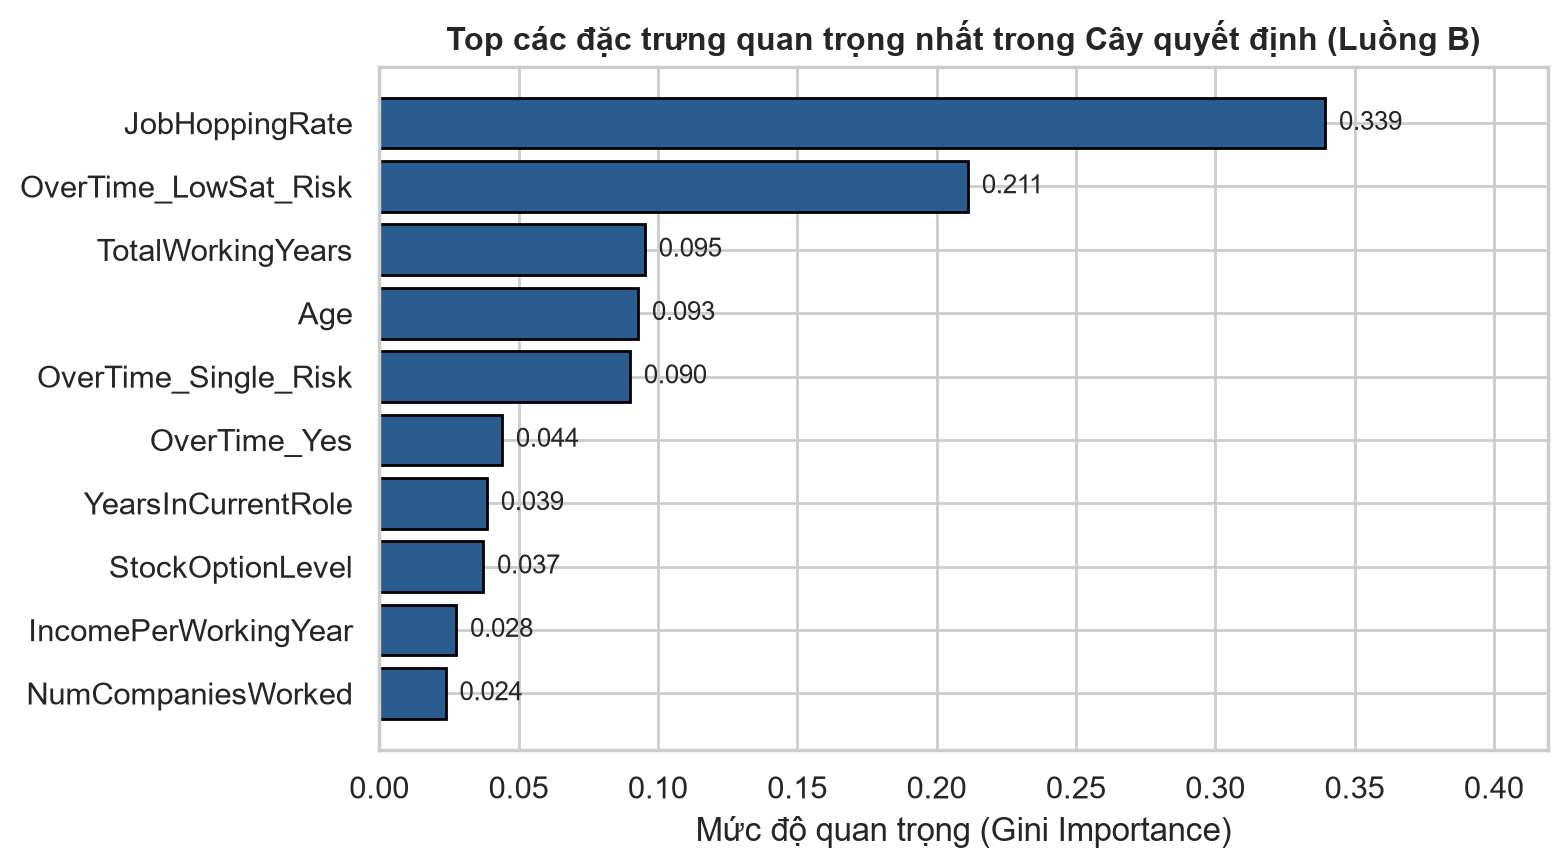

In [9]:
fn_df = pd.read_csv('../outputs/results/error_analysis_FN.csv')
fp_df = pd.read_csv('../outputs/results/error_analysis_FP.csv')

print("1. Các mẫu False Negative (Thực tế Nghỉ việc = 1, Mô hình dự đoán Ở lại = 0) điển hình:")
display(fn_df.head(5))

print("\n2. Các mẫu False Positive (Thực tế Ở lại = 0, Mô hình dự đoán Nghỉ việc = 1) điển hình:")
display(fp_df.head(5))

print("\n3. Mức độ quan trọng của các đặc trưng trong Cây quyết định (Luồng B):")
display(Image(filename='../outputs/figures/fig9_feature_importance.png', width=650))


---
## 5. Kết luận & Khuyến nghị Quản trị Nhân sự
1. **Hiệu quả của Luồng B (Pipeline cải tiến)**:
   - Giúp **K-NN (Tuned)** tăng `F1-score` từ **0.1132** lên **0.2903** (+156%) nhờ loại bỏ chiều nhiễu và chọn lọc 15 đặc trưng quan trọng nhất.
   - Giúp **Decision Tree (Tuned)** tăng `F1-score` từ **0.3529** lên **0.4160** (`Recall` đạt **55.32%**).
   - Giúp **Gaussian Naive Bayes (Tuned, `var_smoothing=0.1`)** đạt hiệu năng cao nhất toàn bộ thí nghiệm với **`F1-score = 0.5714`**, **`Accuracy = 85.71%`**, **`Recall = 59.57%`**, **`Precision = 54.90%`**, và **`ROC-AUC = 0.7686`** (Cross-validation `ROC-AUC = 0.8007`).
2. **Nguyên nhân các trường hợp dự đoán sai (FN & FP)**:
   - **Nhóm FN (Bỏ sót)**: Thường là các nhân sự cấp cao/quản lý (`Research Director`, `Manufacturing Director`, thu nhập > 10,000 USD, không làm thêm giờ, độ hài lòng cao) nghỉ việc do yếu tố bên ngoài dữ liệu (nghỉ hưu sớm, săn đầu người, chuyển chỗ ở gia đình).
   - **Nhóm FP (Báo động giả)**: Thường là nhân viên mới, trẻ tuổi (18–24 tuổi), độc thân, thu nhập thấp (~1,200–2,900 USD) hoặc làm thêm giờ nhiều. Dù họ chưa nghỉ việc tại thời điểm khảo sát, đây thực chất là **nhóm nguy cơ tiềm ẩn rất cao** cần phòng HR quan tâm sớm.
